# Análisis de ventas (Superstore)

**Nombre:** Jimmy Alejandro Martinez Echeverry

**Pregunta central:** ¿Qué categorías, regiones y segmentos generan más ganancia, y cómo afectan los descuentos a la rentabilidad?




# Fundamentos y herramientas

## Selección y justificación del dataset
**Dataset:** Sample Superstore (Kaggle): pedidos de una tienda minorista con producto, cliente, región, ventas, descuento y ganancia.

**Por qué lo elegí:** Elegí el dataset Sample Superstore por su enfoque práctico y realista en el análisis comercial. Evaluar ventas, descuentos y ganancias en distintas regiones y segmentos me permite detectar focos de rentabilidad y de pérdidas, y combinar variables numéricas y categóricas para aplicar lo aprendido en Ciencia de Datos.

**Relación con la carrera:** Este proyecto se conecta con mi formación profesional porque fortalece competencias en análisis e interpretación de datos, programación en Python y toma de decisiones basada en evidencia. Estas herramientas sirven en distintos entornos empresariales para evaluar resultados, detectar oportunidades o problemas y diseñar estrategias que mejoren el desempeño de una organización.

In [32]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("Sample - Superstore.csv", encoding="latin-1")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


##Exploración inicial

In [33]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non

In [34]:
# Tipos de variables
numericas = df.select_dtypes("number").columns.tolist()
categoricas = df.select_dtypes("object").columns.tolist()
print("Numéricas:", numericas)
print("Categóricas:", categoricas)
df.describe().round(2)

Numéricas: ['Row ID', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit']
Categóricas: ['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']


,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00,9994.00,9994.00
mean,4997.50,55190.38,229.86,3.79,0.16,28.66
std,2885.16,32063.69,623.25,2.23,0.21,234.26
min,1.00,1040.00,0.44,1.00,0.00,-6599.98
25%,2499.25,23223.00,17.28,2.00,0.00,1.73
50%,4997.50,56430.50,54.49,3.00,0.20,8.67
75%,7495.75,90008.00,209.94,5.00,0.20,29.36
max,9994.00,99301.00,22638.48,14.00,0.80,8399.98


In [35]:
# Posibles problemas: nulos, duplicados, valores raros
print("Nulos por columna:\n", df.isna().sum()[df.isna().sum() > 0])
print("Filas duplicadas:", df.duplicated().sum())
print("Ventas <= 0:", (df["Sales"] <= 0).sum())
print("Descuentos fuera de [0,1]:", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())
print("Columnas con tipo de fecha como texto:", [c for c in df.columns if "Date" in c])

Nulos por columna:
 Series([], dtype: int64)
Filas duplicadas: 0
Ventas <= 0: 0
Descuentos fuera de [0,1]: 0
Columnas con tipo de fecha como texto: ['Order Date', 'Ship Date']


**Problemas detectados:** En la exploración inicial identifiqué 9,994 registros y 21 columnas, sin valores nulos, duplicados, ventas menores o iguales a cero ni descuentos fuera del rango de 0 a 1. Solo fue necesario convertir Order Date y Ship Date a formato fecha y estandarizar los nombres de columnas (sin espacios ni guiones) para trabajar más cómodamente en Python

## Limpieza y transformación

In [36]:
df_clean = df.copy()

# 1. Nombres de columna sin espacios
df_clean.columns = df_clean.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")

# 2. Duplicados
antes = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Duplicados eliminados: {antes - len(df_clean)}")

# 3. Fechas como datetime
for c in ["Order_Date", "Ship_Date"]:
    df_clean[c] = pd.to_datetime(df_clean[c])

# 4. Nulos: en columnas categóricas se rellenan con 'Desconocido'; en numéricas con la mediana
for c in df_clean.select_dtypes("object"):
    df_clean[c] = df_clean[c].fillna("Desconocido").str.strip()
for c in df_clean.select_dtypes("number"):
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

# 5. Variables nuevas útiles para el análisis
df_clean["Anio"] = df_clean["Order_Date"].dt.year
df_clean["Mes"] = df_clean["Order_Date"].dt.to_period("M").astype(str)
df_clean["Margen"] = df_clean["Profit"] / df_clean["Sales"]
df_clean["Dias_Envio"] = (df_clean["Ship_Date"] - df_clean["Order_Date"]).dt.days
df_clean["Rango_Descuento"] = pd.cut(df_clean["Discount"], [-0.01, 0, 0.2, 0.4, 1],
                                     labels=["0%", "1-20%", "21-40%", ">40%"])
print("Nulos restantes:", df_clean.isna().sum().sum())
df_clean.shape

Duplicados eliminados: 0
Nulos restantes: 0


(9994, 26)

### Resumen del dataset depurado

In [37]:
resumen = pd.DataFrame({
    "tipo": df_clean.dtypes.astype(str),
    "nulos": df_clean.isna().sum(),
    "valores_unicos": df_clean.nunique(),
})
display(resumen)
df_clean.to_csv("superstore_limpio.csv", index=False)

,tipo,nulos,valores_unicos
Row_ID,int64,0,9994
Order_ID,object,0,5009
Order_Date,datetime64[ns],0,1237
Ship_Date,datetime64[ns],0,1334
Ship_Mode,object,0,4
Customer_ID,object,0,793
Customer_Name,object,0,793
Segment,object,0,3
Country,object,0,1
City,object,0,531


# Estadística descriptiva y preprocesamiento

##Tendencia central


In [38]:
num = ["Sales", "Quantity", "Discount", "Profit"]
centrales = pd.DataFrame({
    "media": df_clean[num].mean(),
    "mediana": df_clean[num].median(),
    "moda": df_clean[num].mode().iloc[0],
})
centrales.round(2)

,media,mediana,moda
Sales,229.86,54.49,12.96
Quantity,3.79,3.00,3.00
Discount,0.16,0.20,0.00
Profit,28.66,8.67,0.00


**Interpretación:** La media de Profit es 28.66 USD, pero la mediana es solo 8.67 USD. La media es mayor que la mediana, lo que indica que unos pocos pedidos muy rentables elevan el promedio. En Sales ocurre lo mismo: media de 229.86 USD frente a una mediana de 54.49 USD. Por eso la mediana describe mejor un pedido típico.

##Dispersión

In [39]:
disp = pd.DataFrame({
    "rango": df_clean[num].max() - df_clean[num].min(),
    "varianza": df_clean[num].var(),
    "desv_estandar": df_clean[num].std(),
})
disp["coef_variacion_%"] = disp["desv_estandar"] / df_clean[num].mean().abs() * 100
disp.round(2)

,rango,varianza,desv_estandar,coef_variacion_%
Sales,22638.04,388434.46,623.25,271.14
Quantity,13.00,4.95,2.23,58.72
Discount,0.80,0.04,0.21,132.17
Profit,14999.95,54877.80,234.26,817.47


**Interpretación:** El coeficiente de variación de Profit es 817.47 %, y el de Sales es 271.14 %. Son valores muy altos: los pedidos son muy distintos entre sí, y hay desde pérdidas fuertes hasta ganancias muy grandes. Por eso la media por sí sola no resume bien estas variables, y conviene apoyarse en la mediana y en comparaciones por grupo.

##Distribución de las variables

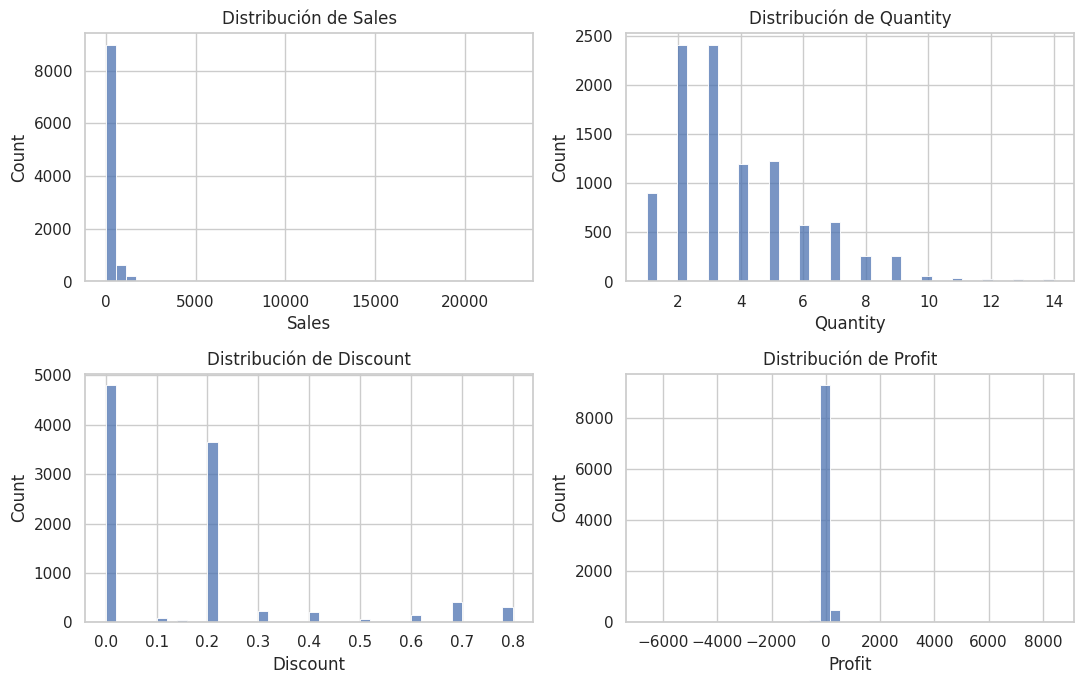

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), num):
    sns.histplot(df_clean[col], bins=40, ax=ax)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout(); plt.show()

##Comparación entre grupos

In [41]:
for grupo in ["Category", "Region", "Segment"]:
    tabla = df_clean.groupby(grupo).agg(
        ventas_total=("Sales", "sum"),
        ganancia_total=("Profit", "sum"),
        ganancia_media=("Profit", "mean"),
        ganancia_mediana=("Profit", "median"),
        ganancia_std=("Profit", "std"),
        descuento_medio=("Discount", "mean"),
    ).round(2)
    display(tabla)

,ventas_total,ganancia_total,ganancia_media,ganancia_mediana,ganancia_std,descuento_medio
Category,,,,,,
Furniture,741999.80,18451.27,8.70,7.77,136.05,0.17
Office Supplies,719047.03,122490.80,20.33,6.88,164.89,0.16
Technology,836154.03,145454.95,78.75,25.02,428.82,0.13


,ventas_total,ganancia_total,ganancia_media,ganancia_mediana,ganancia_std,descuento_medio
Region,,,,,,
Central,501239.89,39706.36,17.09,5.18,291.49,0.24
East,678781.24,91522.78,32.14,8.17,251.61,0.15
South,391721.90,46749.43,28.86,9.07,212.89,0.15
West,725457.82,108418.45,33.85,11.17,174.11,0.11


,ventas_total,ganancia_total,ganancia_media,ganancia_mediana,ganancia_std,descuento_medio
Segment,,,,,,
Consumer,1161401.34,134119.21,25.84,8.38,242.59,0.16
Corporate,706146.37,91979.13,30.46,8.69,231.99,0.16
Home Office,429653.15,60298.68,33.82,9.10,212.38,0.15


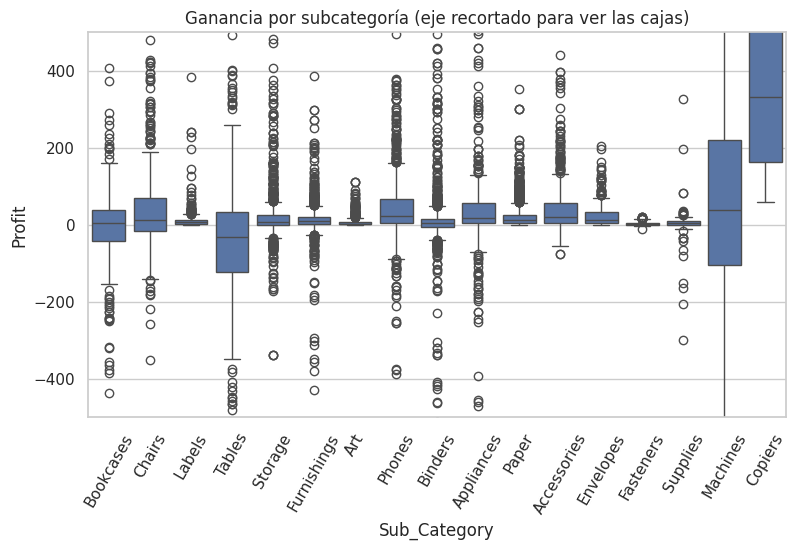

In [42]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Sub_Category", y="Profit")
plt.xticks(rotation=60); plt.ylim(-500, 500)
plt.title("Ganancia por subcategoría (eje recortado para ver las cajas)")
plt.show()

##Relación entre descuento y ganancia

In [43]:
print("Correlación Discount vs Profit:", round(df_clean["Discount"].corr(df_clean["Profit"]), 3))
print(df_clean.groupby("Rango_Descuento", observed=True)["Profit"].agg(["count", "mean", "median"]).round(2))

Correlación Discount vs Profit: -0.219
                 count    mean  median
Rango_Descuento                       
0%                4798   66.90   16.00
1-20%             3803   26.50    6.74
21-40%             460  -77.86  -36.11
>40%               933 -106.71  -13.58


La correlación entre Discount y Profit es -0.219, es decir, negativa pero débil. Una correlación lineal resume mal este caso porque la relación no es una línea recta: la tabla por rangos muestra el patrón real. Sin descuento la ganancia media es de 66.90 USD, con 1-20 % baja a 26.50 USD, y con 21-40 % pasa a -77.86 USD. Con más de 40 % la media es de -106.71 USD. Esto describe una asociación, no prueba por sí solo que el descuento cause la pérdida: los descuentos altos podrían concentrarse en productos que ya tenían poco margen.

##Outliers (método IQR)

In [44]:
def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)

for col in ["Sales", "Profit"]:
    mask = outliers_iqr(df_clean[col])
    print(f"{col}: {mask.sum()} outliers ({mask.mean():.1%} de las filas)")

out_perdida = df_clean[outliers_iqr(df_clean["Profit"]) & (df_clean["Profit"] < 0)]
out_perdida.sort_values("Profit").head(10)[["Product_Name", "Sub_Category", "Sales", "Discount", "Profit"]]

Sales: 1167 outliers (11.7% de las filas)
Profit: 1881 outliers (18.8% de las filas)


,Product_Name,Sub_Category,Sales,Discount,Profit
7772,Cubify CubeX 3D Printer Double Head Print,Machines,4499.985,0.7,-6599.9780
683,Cubify CubeX 3D Printer Triple Head Print,Machines,7999.980,0.5,-3839.9904
9774,GBC DocuBind P400 Electric Binding System,Binders,2177.584,0.8,-3701.8928
3011,Lexmark MX611dhe Monochrome Laser Printer,Machines,2549.985,0.7,-3399.9800
4991,Ibico EPK-21 Electric Binding System,Binders,1889.990,0.8,-2929.4845
3151,Cubify CubeX 3D Printer Double Head Print,Machines,1799.994,0.7,-2639.9912
5310,Fellowes PB500 Electric Punch Plastic Comb Bin...,Binders,1525.188,0.8,-2287.7820
9639,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Tables,4297.644,0.4,-1862.3124
1199,GBC DocuBind P400 Electric Binding System,Binders,1088.792,0.8,-1850.9464
2697,Cisco TelePresence System EX90 Videoconferenci...,Machines,22638.480,0.5,-1811.0784


El método IQR detectó 1167 outliers en Sales y 1881 en Profit. Decidí conservarlos porque no parecen errores de captura: son ventas grandes y pérdidas reales del negocio, y eliminarlos ocultaría justamente el problema que quiero estudiar. La consecuencia es que sesgan la media y perjudican a la regresión lineal.

##Hipótesis
A partir de la exploración y de la asociación negativa entre descuentos y ganancia, planteo estas hipótesis:
1.  Umbral de descuento. Los pedidos con descuento mayor al 20 % tienen una ganancia menor, y en promedio negativa, frente a los demás.
2.  Volumen y margen. Algunas subcategorías venden mucho pero dejan poca o ninguna ganancia.
3.  Región y segmento. La ganancia por pedido difiere entre regiones y segmentos de clientes.


#Modelado matemático y storytelling

##Visualizaciones finales

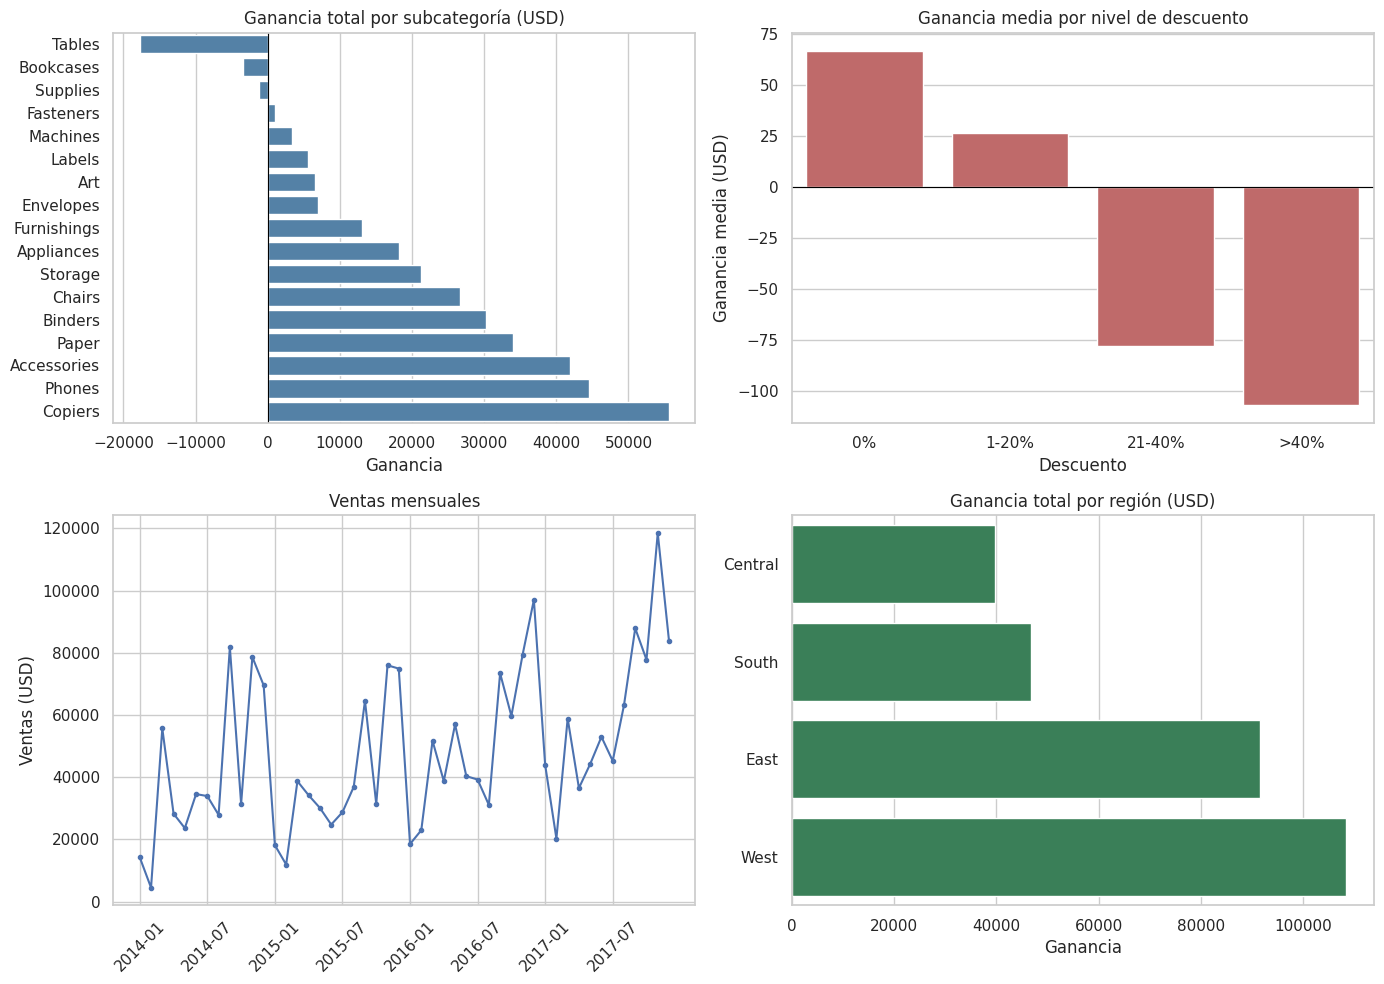

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# a) Ganancia total por subcategoría
g = df_clean.groupby("Sub_Category")["Profit"].sum().sort_values()
sns.barplot(x=g.values, y=g.index, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(0, color="black", lw=0.8)
axes[0, 0].set_title("Ganancia total por subcategoría (USD)")
axes[0, 0].set_xlabel("Ganancia"); axes[0, 0].set_ylabel("")

# b) Ganancia media según nivel de descuento
sns.barplot(data=df_clean, x="Rango_Descuento", y="Profit", errorbar=None, ax=axes[0, 1], color="indianred")
axes[0, 1].axhline(0, color="black", lw=0.8)
axes[0, 1].set_title("Ganancia media por nivel de descuento")
axes[0, 1].set_xlabel("Descuento"); axes[0, 1].set_ylabel("Ganancia media (USD)")

# c) Evolución mensual de ventas
m = df_clean.groupby("Mes")["Sales"].sum()
axes[1, 0].plot(m.index, m.values, marker="o", ms=3)
axes[1, 0].set_xticks(m.index[::6]); axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].set_title("Ventas mensuales"); axes[1, 0].set_ylabel("Ventas (USD)")

# d) Ganancia por región
r = df_clean.groupby("Region")["Profit"].sum().sort_values()
sns.barplot(x=r.values, y=r.index, ax=axes[1, 1], color="seagreen")
axes[1, 1].set_title("Ganancia total por región (USD)")
axes[1, 1].set_xlabel("Ganancia"); axes[1, 1].set_ylabel("")

plt.tight_layout(); plt.show()


In [46]:
for grupo in ["Category", "Region", "Segment"]:
    print(df_clean.groupby(grupo)[["Sales", "Profit"]].sum().round(0).sort_values("Profit", ascending=False), "\n")

print("Ganancia total por subcategoría:")
print(df_clean.groupby("Sub_Category")["Profit"].sum().sort_values().round(0), "\n")

print("Descuento medio y % de pedidos con descuento > 20% por región:")
reg = df_clean.assign(alto=df_clean["Discount"] > 0.2).groupby("Region").agg(
    descuento_medio=("Discount", "mean"), pct_desc_alto=("alto", "mean")).round(3)
print(reg)

                    Sales    Profit
Category                           
Technology       836154.0  145455.0
Office Supplies  719047.0  122491.0
Furniture        742000.0   18451.0 

            Sales    Profit
Region                     
West     725458.0  108418.0
East     678781.0   91523.0
South    391722.0   46749.0
Central  501240.0   39706.0 

                 Sales    Profit
Segment                         
Consumer     1161401.0  134119.0
Corporate     706146.0   91979.0
Home Office   429653.0   60299.0 

Ganancia total por subcategoría:
Sub_Category
Tables        -17725.0
Bookcases      -3473.0
Supplies       -1189.0
Fasteners        950.0
Machines        3385.0
Labels          5546.0
Art             6528.0
Envelopes       6964.0
Furnishings    13059.0
Appliances     18138.0
Storage        21279.0
Chairs         26590.0
Binders        30222.0
Paper          34054.0
Accessories    41937.0
Phones         44516.0
Copiers        55618.0
Name: Profit, dtype: float64 

Descuento med

##Storytelling
Superstore vende mucho, pero vender más no garantiza ganar más. La rentabilidad depende sobre todo de la política de descuentos y de la mezcla de productos.

**El punto de quiebre de los descuentos.** Los pedidos sin descuento o con descuentos de hasta 20 % tienen ganancia media positiva (66.90 y 26.50 USD). Al superar el 20 %, la ganancia media pasa a negativa (-77.86 USD entre 21 y 40 %, y -106.71 USD por encima de 40 %).

- **Por categoría.** Technology es la que más ganancia aporta, con 145,455 USD en ganancias y 836,154 USD en ventas, seguida de Office Supplies. Furniture tiene ventas altas pero una ganancia de solo 18,451 USD. Las subcategorías con pérdidas son Tables, Bookcases y Supplies, con -22,387 USD en total.

- **Por región y segmento.** West y East concentran la mayor parte de la ganancia total. Central  es la más débil, con 39,706 USD, y su descuento medio es 0.240, frente a 0.13 en las demás regiones. En segmentos, Consumer lidera en ventas con 1,161,401 USD y en ganancias con 134,119 USD, seguido de Corporate y Home Office.

- **Decisión recomendada.** Limitar los descuentos por encima del 20 %, empezando por las subcategorías con pérdidas y por la región más débil, y priorizar los productos de mayor margen.


##Modelo predictivo: regresión lineal

**Objetivo:** predecir la ganancia (`Profit`) de un pedido a partir de sus ventas, descuento, cantidad y categoría.

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X = pd.get_dummies(df_clean[["Sales", "Discount", "Quantity", "Category"]], drop_first=True)
y = df_clean["Profit"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression().fit(X_train, y_train)
pred = modelo.predict(X_test)

print(f"R²:   {r2_score(y_test, pred):.3f}")
print(f"MAE:  {mean_absolute_error(y_test, pred):.2f} USD")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.2f} USD")

coef = pd.Series(modelo.coef_, index=X.columns).round(2)
print("\nCoeficientes:\n", coef)

R²:   -0.748
MAE:  69.54 USD
RMSE: 291.12 USD

Coeficientes:
 Sales                         0.27
Discount                   -205.34
Quantity                     -6.92
Category_Office Supplies     64.93
Category_Technology          41.04
dtype: float64


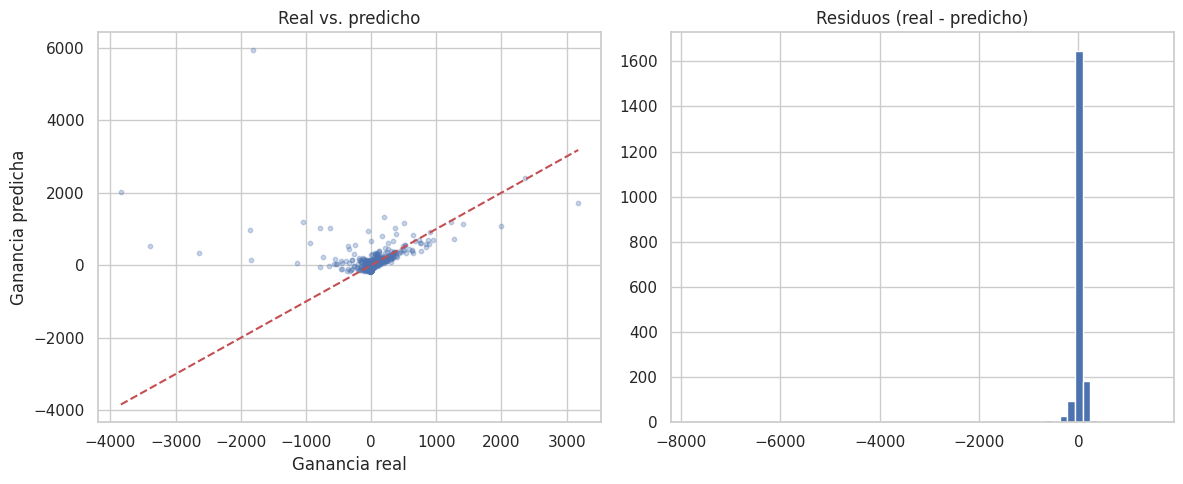

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, pred, alpha=0.3, s=10)
lim = [y_test.min(), y_test.max()]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlabel("Ganancia real"); axes[0].set_ylabel("Ganancia predicha")
axes[0].set_title("Real vs. predicho")
axes[1].hist(y_test - pred, bins=60); axes[1].set_title("Residuos (real - predicho)")
plt.tight_layout(); plt.show()

**Cómo interpretar el modelo**

- R² = -0.748. Un R² negativo significa que el modelo predice peor que usar siempre el promedio de la ganancia. Una suma lineal de Sales, Discount, Quantity y Category no basta para explicar la ganancia.

- Coeficiente de Discount (-205.34). Manteniendo lo demás constante, subir el descuento en 10 puntos porcentuales (0.10) baja la ganancia esperada en unos 20.5 USD por pedido. Es una tendencia útil de leer, pero no hay que sobreinterpretarla en un modelo que predice mal.

-  Limitaciones. (1) hay valores extremos en ventas y pérdidas, (2) no se conoce el costo de cada producto y (3) falta una interacción, porque el efecto del descuento depende del monto de la venta (Sales × Discount).



## Aplicación profesional
En una empresa, este flujo de trabajo permite pasar de decidir por intuición a decidir con datos. Con Python y estadística es posible auditar políticas de precios, detectar pérdidas escondidas tras altos volúmenes de venta y crear alertas tempranas para pedidos no rentables antes de que afecten el resultado financiero.

## Conclusión
El análisis del dataset Superstore responde la pregunta central así:
Rentabilidad por grupos. Technology es la categoría más rentable, mientras que Furniture deja poco margen. West y East  encabezan las utilidades regionales, y Central tiene el peor resultado. Consumer es el segmento más valioso por volumen y ganancia.

Efecto de los descuentos. Existe una correlación negativa débil (-0.219) y una caída clara de la ganancia media al pasar del 20 % de descuento: de 26.50 USD (1-20 %) a -77.86 USD (21-40 %).

Modelo predictivo. El modelo lineal simple obtuvo un R² de -0.748, es decir, predice peor que usar el promedio. Esto indica que ventas, descuento, cantidad y categoría no bastan para explicar la ganancia, y que faltan variables como el costo del producto y términos de interacción (Sales × Discount).

Recomendación. Fijar un tope de descuento de 20 % en promociones estándar, pedir aprobación gerencial para descuentos mayores en las subcategorías con pérdidas y concentrar las campañas en los productos y regiones de mayor margen.